In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

os.makedirs("../dataset", exist_ok=True)
os.makedirs("../plots", exist_ok=True)

np.random.seed(42)
n = 1000

student_id = [f"STU{1001 + i}" for i in range(n)]
gender = np.random.choice(["Male", "Female"], size=n, p=[0.52, 0.48])
attendance = np.clip(np.random.normal(82, 10, n), 50, 100).round(1)
study_hours = np.clip(np.random.normal(3.5, 1.2, n), 0.5, 8.0).round(1)
sleep_hours = np.clip(np.random.normal(6.8, 1.0, n), 4.0, 9.5).round(1)
extracurricular = np.random.choice(["Yes", "No"], size=n, p=[0.4, 0.6])
prev_sem_marks = np.clip(np.random.normal(70, 12, n), 35, 98).round(1)

assignment_score = np.clip(
    0.4 * prev_sem_marks + 2.5 * study_hours + 0.2 * attendance + np.random.normal(15, 5, n), 40, 100
).round(1)

internal_marks = np.clip(
    0.35 * prev_sem_marks + 0.35 * assignment_score + 0.15 * attendance + np.random.normal(8, 4, n), 35, 100
).round(1)

final_marks = np.clip(
    0.25 * attendance
    + 2.2 * study_hours
    + 0.20 * assignment_score
    + 0.30 * internal_marks
    + 0.22 * prev_sem_marks
    + np.where(extracurricular == "Yes", 1.5, 0.0)
    + np.random.normal(-8, 3.5, n),
    30,
    100
).round(1)

remarks = []
for att, hrs, fm in zip(attendance, study_hours, final_marks):
    if fm >= 80 and att >= 75:
        remarks.append("Consistent high attendance and disciplined daily study habits resulted in distinction-level examination performance.")
    elif fm >= 60:
        remarks.append("Satisfactory academic progress with steady internal scores and moderate self-study consistency across the semester.")
    else:
        remarks.append("Needs targeted academic mentoring, improved lecture attendance, and structured daily revision before final exams.")

df_raw = pd.DataFrame({
    "Student_ID": student_id,
    "Gender": gender,
    "Attendance": attendance,
    "Study_Hours": study_hours,
    "Assignment_Score": assignment_score,
    "Internal_Marks": internal_marks,
    "Previous_Semester_Marks": prev_sem_marks,
    "Sleep_Hours": sleep_hours,
    "Extracurricular_Activities": extracurricular,
    "Final_Marks": final_marks,
    "Performance_Remark": remarks
})

# Inject 15 missing values and 10 duplicate rows for Task 1 preprocessing
for col in ["Attendance", "Study_Hours", "Sleep_Hours"]:
    df_raw.loc[np.random.choice(n, 5, replace=False), col] = np.nan

df_raw = pd.concat([df_raw, df_raw.iloc[:10]], ignore_index=True)
df_raw.to_csv("../dataset/student_performance_1000.csv", index=False)

total_words = df_raw["Performance_Remark"].str.split().str.len().sum()
print(f"Dataset Created -> Raw Rows: {len(df_raw)} | Descriptive Words: {total_words}")
print("Reg No: 311824102302")

Dataset Created -> Raw Rows: 1010 | Descriptive Words: 14010
Reg No: 311824102302


In [2]:
df = pd.read_csv("../dataset/student_performance_1000.csv")
print("Initial Shape:", df.shape)
print("\nMissing Values Before Cleaning:\n", df.isnull().sum())
print("\nDuplicate Rows Found:", df.duplicated().sum())

# Remove duplicates
df = df.drop_duplicates().reset_index(drop=True)

# Identify numerical and categorical variables
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

# Impute missing numerical values with median
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

print("\nCleaned Dataset Shape:", df.shape)
print("Numerical Variables:", num_cols)
print("Categorical Variables:", cat_cols)
print("Reg No: 311824102302")

Initial Shape: (1010, 11)

Missing Values Before Cleaning:
 Student_ID                    0
Gender                        0
Attendance                    5
Study_Hours                   5
Assignment_Score              0
Internal_Marks                0
Previous_Semester_Marks       0
Sleep_Hours                   5
Extracurricular_Activities    0
Final_Marks                   0
Performance_Remark            0
dtype: int64

Duplicate Rows Found: 10

Cleaned Dataset Shape: (1000, 11)
Numerical Variables: ['Attendance', 'Study_Hours', 'Assignment_Score', 'Internal_Marks', 'Previous_Semester_Marks', 'Sleep_Hours', 'Final_Marks']
Categorical Variables: ['Student_ID', 'Gender', 'Extracurricular_Activities', 'Performance_Remark']
Reg No: 311824102302


,Mean,Median,Mode,Variance,Std_Dev
Attendance,82.83,82.9,100.0,91.43,9.56
Study_Hours,3.51,3.5,3.5,1.33,1.15
Assignment_Score,68.05,68.1,65.5,58.03,7.62
Internal_Marks,68.58,68.5,67.0,59.60,7.72
Previous_Semester_Marks,69.75,69.8,98.0,136.70,11.69
Sleep_Hours,6.79,6.8,6.7,1.06,1.03
Final_Marks,70.67,70.9,69.4,68.56,8.28


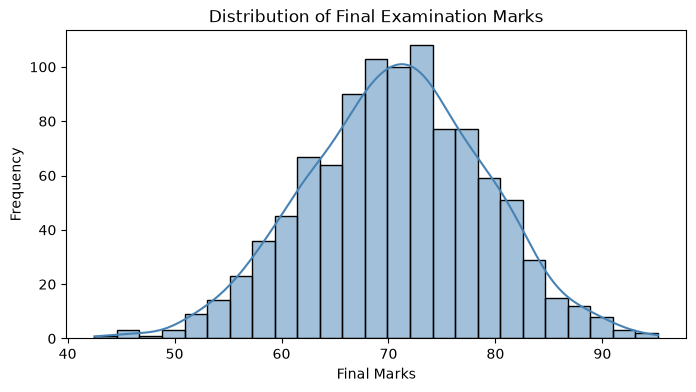

Population Mean: 70.67
Random Sample Mean (n=100): 69.89
Systematic Sample Mean (every 10th): 71.48
Stratified Sample Mean (by Gender): 70.75

Two-Sample T-Test (Extracurricular Yes vs No): t = 2.7953, p-value = 0.0053
Decision: Reject H0 (Statistically Significant Difference)
Reg No: 311824102302


In [3]:
# 1. Mean, Median, Mode, Variance, Standard Deviation
desc_stats = pd.DataFrame({
    "Mean": df[num_cols].mean(),
    "Median": df[num_cols].median(),
    "Mode": df[num_cols].mode().iloc[0],
    "Variance": df[num_cols].var(),
    "Std_Dev": df[num_cols].std()
}).round(2)
display(desc_stats)

# 2. Marks Distribution Plot
plt.figure(figsize=(8, 4))
sns.histplot(df["Final_Marks"], kde=True, bins=25, color="steelblue")
plt.title("Distribution of Final Examination Marks")
plt.xlabel("Final Marks")
plt.ylabel("Frequency")
plt.savefig("../plots/marks_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

# 3. Sampling Techniques (Random, Systematic, Stratified)
random_sample = df.sample(n=100, random_state=42)
systematic_sample = df.iloc[::10]
stratified_sample = df.groupby("Gender", group_keys=False).apply(lambda x: x.sample(frac=0.1, random_state=42))

print(f"Population Mean: {df['Final_Marks'].mean():.2f}")
print(f"Random Sample Mean (n=100): {random_sample['Final_Marks'].mean():.2f}")
print(f"Systematic Sample Mean (every 10th): {systematic_sample['Final_Marks'].mean():.2f}")
print(f"Stratified Sample Mean (by Gender): {stratified_sample['Final_Marks'].mean():.2f}")

# 4. Hypothesis Testing (Independent Two-Sample T-Test)
group_yes = df[df["Extracurricular_Activities"] == "Yes"]["Final_Marks"]
group_no = df[df["Extracurricular_Activities"] == "No"]["Final_Marks"]

t_stat, p_val = stats.ttest_ind(group_yes, group_no)
print(f"\nTwo-Sample T-Test (Extracurricular Yes vs No): t = {t_stat:.4f}, p-value = {p_val:.4f}")
print("Decision:", "Reject H0 (Statistically Significant Difference)" if p_val < 0.05 else "Fail to Reject H0")
print("Reg No: 311824102302")

P(Final_Marks > 80) = 0.1350
P(Attendance > 75%) = 0.8010
Conditional Probability P(Marks > 80 | Attendance > 75%) = 0.1586
Bayes' Theorem P(Attendance > 75% | Marks > 80) = 0.9407


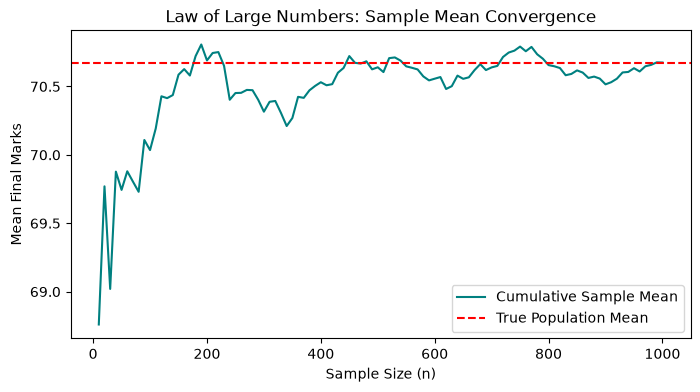

Reg No: 311824102302


In [4]:
event_A = df["Final_Marks"] > 80
event_B = df["Attendance"] > 75

P_A = event_A.mean()
P_B = event_B.mean()
P_A_and_B = (event_A & event_B).mean()

# Conditional Probability: P(Final_Marks > 80 | Attendance > 75%)
P_A_given_B = P_A_and_B / P_B

# Bayes' Theorem: P(Attendance > 75% | Final_Marks > 80)
P_B_given_A = (P_A_given_B * P_B) / P_A

print(f"P(Final_Marks > 80) = {P_A:.4f}")
print(f"P(Attendance > 75%) = {P_B:.4f}")
print(f"Conditional Probability P(Marks > 80 | Attendance > 75%) = {P_A_given_B:.4f}")
print(f"Bayes' Theorem P(Attendance > 75% | Marks > 80) = {P_B_given_A:.4f}")

# Law of Large Numbers Convergence
sample_sizes = np.arange(10, len(df) + 1, 10)
cumulative_means = [df["Final_Marks"].iloc[:k].mean() for k in sample_sizes]

plt.figure(figsize=(8, 4))
plt.plot(sample_sizes, cumulative_means, label="Cumulative Sample Mean", color="teal")
plt.axhline(df["Final_Marks"].mean(), color="red", linestyle="--", label="True Population Mean")
plt.title("Law of Large Numbers: Sample Mean Convergence")
plt.xlabel("Sample Size (n)")
plt.ylabel("Mean Final Marks")
plt.legend()
plt.savefig("../plots/law_of_large_numbers.png", dpi=300, bbox_inches="tight")
plt.show()
print("Reg No: 311824102302")

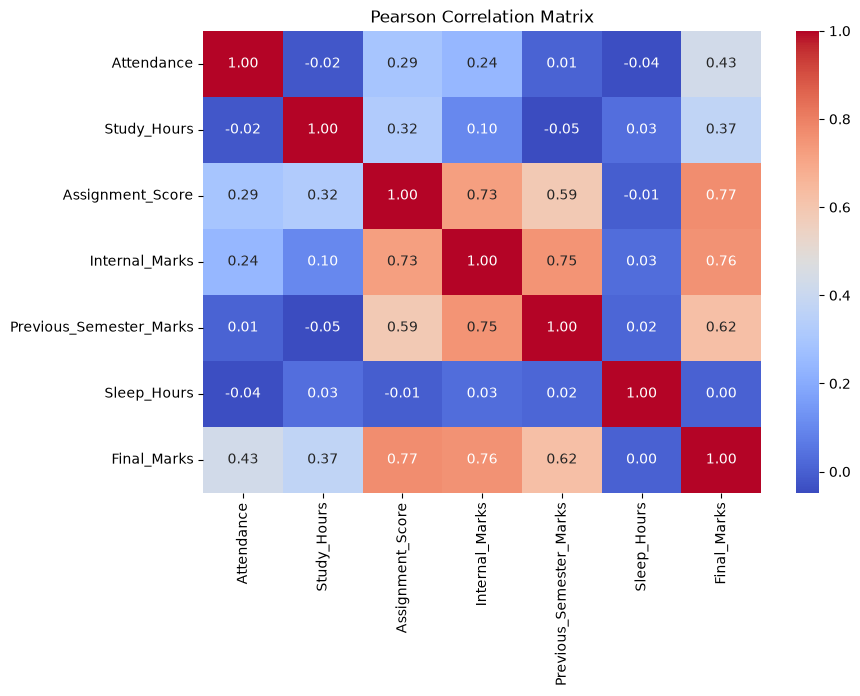

Strongest Factors Associated with Final_Marks (Pearson):
Final_Marks                1.0000
Assignment_Score           0.7703
Internal_Marks             0.7563
Previous_Semester_Marks    0.6244
Attendance                 0.4299
Study_Hours                0.3726
Sleep_Hours                0.0047
Name: Final_Marks, dtype: float64

Strongest Factors Associated with Final_Marks (Spearman):
Final_Marks                1.0000
Assignment_Score           0.7600
Internal_Marks             0.7335
Previous_Semester_Marks    0.5952
Attendance                 0.4239
Study_Hours                0.3763
Sleep_Hours                0.0185
Name: Final_Marks, dtype: float64
Reg No: 311824102302


In [5]:
pearson_corr = df[num_cols].corr(method="pearson")
spearman_corr = df[num_cols].corr(method="spearman")

plt.figure(figsize=(9, 6))
sns.heatmap(pearson_corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Pearson Correlation Matrix")
plt.savefig("../plots/correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

print("Strongest Factors Associated with Final_Marks (Pearson):")
print(pearson_corr["Final_Marks"].sort_values(ascending=False).round(4))

print("\nStrongest Factors Associated with Final_Marks (Spearman):")
print(spearman_corr["Final_Marks"].sort_values(ascending=False).round(4))
print("Reg No: 311824102302")

In [6]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

# 1. Simple Linear Regression (Attendance -> Final_Marks)
slr = LinearRegression()
slr.fit(train_df[["Attendance"]], train_df["Final_Marks"])
y_pred_slr = slr.predict(test_df[["Attendance"]])

# 2. Multiple Linear Regression (5 predictors -> Final_Marks)
features = ["Attendance", "Study_Hours", "Assignment_Score", "Internal_Marks", "Previous_Semester_Marks"]
mlr = LinearRegression()
mlr.fit(train_df[features], train_df["Final_Marks"])
y_pred_mlr = mlr.predict(test_df[features])

def evaluate(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return {"Model": name, "MAE": round(mae, 3), "MSE": round(mse, 3), "RMSE": round(rmse, 3), "R2_Score": round(r2, 4)}

comparison_table = pd.DataFrame([
    evaluate(test_df["Final_Marks"], y_pred_slr, "Simple Linear Regression (Attendance)"),
    evaluate(test_df["Final_Marks"], y_pred_mlr, "Multiple Linear Regression (5 Features)")
])
display(comparison_table)
print("Reg No: 311824102302")

,Model,MAE,MSE,RMSE,R2_Score
0,Simple Linear Regression (Attendance),6.075,56.622,7.525,0.1620
1,Multiple Linear Regression (5 Features),2.877,13.054,3.613,0.8068


Reg No: 311824102302


In [7]:
X_raw = train_df[features].values
y_vec = train_df["Final_Marks"].values.reshape(-1, 1)

# Add bias column of 1s for intercept
X_mat = np.hstack([np.ones((X_raw.shape[0], 1)), X_raw])

# Vector Operations on Student 1 & Student 2
v1, v2 = X_raw[0], X_raw[1]
print("Student 1 Feature Vector:", v1)
print("Student 2 Feature Vector:", v2)
print("Vector Addition (v1 + v2):", v1 + v2)
print("Dot Product (v1 · v2):", round(np.dot(v1, v2), 2))

# Normal Equation: theta = (X^T X)^(-1) X^T y
theta_normal = np.linalg.inv(X_mat.T @ X_mat) @ (X_mat.T @ y_vec)

print("\nNormal Equation Parameters (Intercept + 5 Features):", theta_normal.flatten().round(4))
print("Scikit-Learn Parameters (Intercept + 5 Features):   ", np.insert(mlr.coef_, 0, mlr.intercept_).round(4))
print("Reg No: 311824102302")

Student 1 Feature Vector: [73.1  4.6 61.2 70.9 71.9]
Student 2 Feature Vector: [68.9  4.  70.3 69.  76. ]
Vector Addition (v1 + v2): [142.    8.6 131.5 139.9 147.9]
Dot Product (v1 · v2): 19713.85

Normal Equation Parameters (Intercept + 5 Features): [-9.0046  0.2602  2.1458  0.2229  0.2934  0.219 ]
Scikit-Learn Parameters (Intercept + 5 Features):    [-9.0046  0.2602  2.1458  0.2229  0.2934  0.219 ]
Reg No: 311824102302


In [8]:
X_raw = train_df[features].values
y_vec = train_df["Final_Marks"].values.reshape(-1, 1)

# Add bias column of 1s for intercept
X_mat = np.hstack([np.ones((X_raw.shape[0], 1)), X_raw])

# Vector Operations on Student 1 & Student 2
v1, v2 = X_raw[0], X_raw[1]
print("Student 1 Feature Vector:", v1)
print("Student 2 Feature Vector:", v2)
print("Vector Addition (v1 + v2):", v1 + v2)
print("Dot Product (v1 · v2):", round(np.dot(v1, v2), 2))

# Normal Equation: theta = (X^T X)^(-1) X^T y
theta_normal = np.linalg.inv(X_mat.T @ X_mat) @ (X_mat.T @ y_vec)

print("\nNormal Equation Parameters (Intercept + 5 Features):", theta_normal.flatten().round(4))
print("Scikit-Learn Parameters (Intercept + 5 Features):   ", np.insert(mlr.coef_, 0, mlr.intercept_).round(4))
print("Reg No: 311824102302")

Student 1 Feature Vector: [73.1  4.6 61.2 70.9 71.9]
Student 2 Feature Vector: [68.9  4.  70.3 69.  76. ]
Vector Addition (v1 + v2): [142.    8.6 131.5 139.9 147.9]
Dot Product (v1 · v2): 19713.85

Normal Equation Parameters (Intercept + 5 Features): [-9.0046  0.2602  2.1458  0.2229  0.2934  0.219 ]
Scikit-Learn Parameters (Intercept + 5 Features):    [-9.0046  0.2602  2.1458  0.2229  0.2934  0.219 ]
Reg No: 311824102302


Initial Cost J(theta): 2534.10 -> Final Cost after 300 epochs: 6.89
Optimized Parameters (Standardized): [70.707   2.5046  2.486   1.737   2.2791  2.5288]


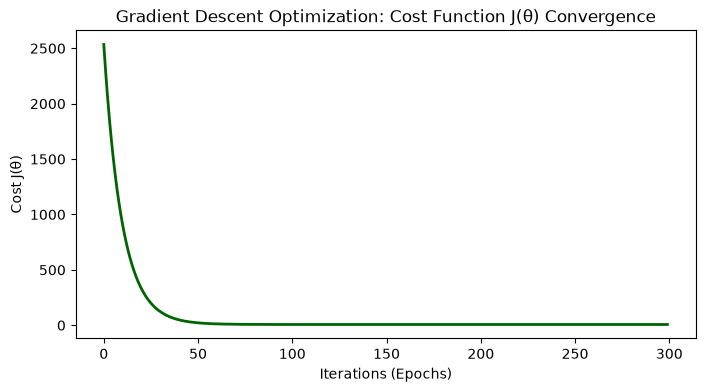

Reg No: 311824102302


In [9]:
# Standardize features for smooth gradient descent convergence
X_scaled = (X_raw - X_raw.mean(axis=0)) / X_raw.std(axis=0)
X_gd = np.hstack([np.ones((X_scaled.shape[0], 1)), X_scaled])

m = len(y_vec)
theta = np.zeros((X_gd.shape[1], 1))
learning_rate = 0.05
epochs = 300
cost_history = []

for epoch in range(epochs):
    predictions = X_gd @ theta
    errors = predictions - y_vec
    cost = (1 / (2 * m)) * np.sum(errors ** 2)
    gradients = (1 / m) * (X_gd.T @ errors)
    theta = theta - learning_rate * gradients
    cost_history.append(cost)

print(f"Initial Cost J(theta): {cost_history[0]:.2f} -> Final Cost after {epochs} epochs: {cost_history[-1]:.2f}")
print("Optimized Parameters (Standardized):", theta.flatten().round(4))

plt.figure(figsize=(8, 4))
plt.plot(range(epochs), cost_history, color="darkgreen", lw=2)
plt.title("Gradient Descent Optimization: Cost Function J(θ) Convergence")
plt.xlabel("Iterations (Epochs)")
plt.ylabel("Cost J(θ)")
plt.savefig("../plots/gradient_descent_cost.png", dpi=300, bbox_inches="tight")
plt.show()
print("Reg No: 311824102302")

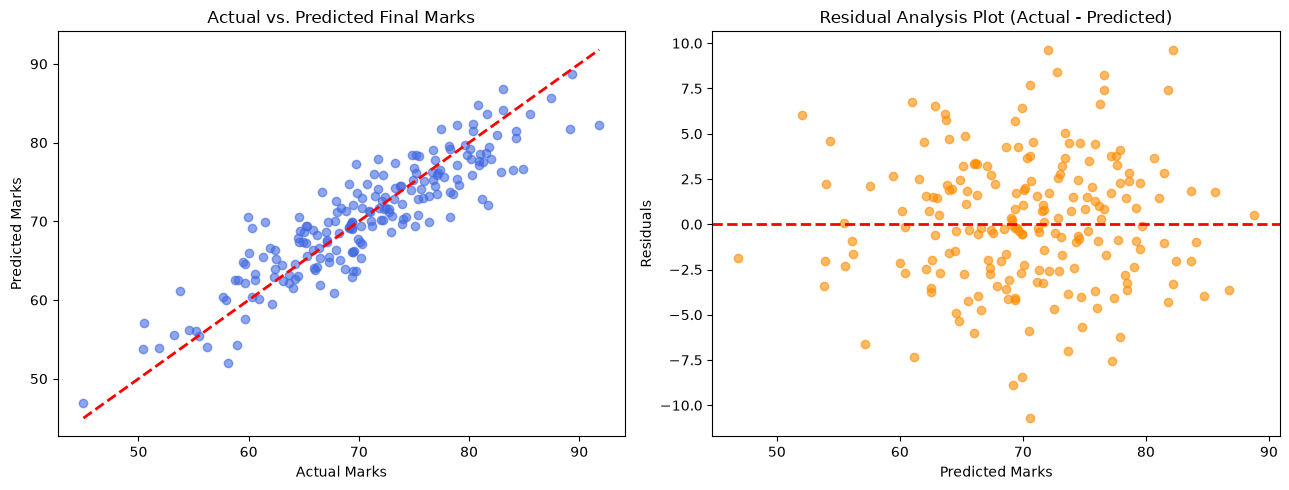

Mean Residual: 0.1502 (Near-zero confirms unbiased predictions)
Overestimated Predictions (Predicted > Actual): 100 / 200
Underestimated Predictions (Predicted < Actual): 100 / 200
Reg No: 311824102302


In [10]:
y_actual = test_df["Final_Marks"].values
residuals = y_actual - y_pred_mlr

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_actual, y_pred_mlr, alpha=0.6, color="royalblue")
axes[0].plot([y_actual.min(), y_actual.max()], [y_actual.min(), y_actual.max()], "r--", lw=2)
axes[0].set_title("Actual vs. Predicted Final Marks")
axes[0].set_xlabel("Actual Marks")
axes[0].set_ylabel("Predicted Marks")

axes[1].scatter(y_pred_mlr, residuals, alpha=0.6, color="darkorange")
axes[1].axhline(0, color="red", linestyle="--", lw=2)
axes[1].set_title("Residual Analysis Plot (Actual - Predicted)")
axes[1].set_xlabel("Predicted Marks")
axes[1].set_ylabel("Residuals")

plt.tight_layout()
plt.savefig("../plots/actual_vs_predicted_residuals.png", dpi=300, bbox_inches="tight")
plt.show()

overestimated = np.sum(residuals < 0)
underestimated = np.sum(residuals > 0)

print(f"Mean Residual: {np.mean(residuals):.4f} (Near-zero confirms unbiased predictions)")
print(f"Overestimated Predictions (Predicted > Actual): {overestimated} / {len(residuals)}")
print(f"Underestimated Predictions (Predicted < Actual): {underestimated} / {len(residuals)}")
print("Reg No: 311824102302")

In [11]:
# Test Prediction on a Sample New Student
test_student = pd.DataFrame(
    [[88.0, 4.5, 85.0, 82.0, 78.0]],
    columns=["Attendance", "Study_Hours", "Assignment_Score", "Internal_Marks", "Previous_Semester_Marks"]
)
pred = mlr.predict(test_student)[0]
print(f"Sample Student Predicted Final Marks: {pred:.2f} / 100")
print("Reg No: 311824102302")

Sample Student Predicted Final Marks: 83.64 / 100
Reg No: 311824102302
